# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0–3 — gate C liveness: `gate-current-sanity-check` (B = 0, V_si = 0, T = 1.17 K)

**Read:** device alive on the provided contacts — drain current 9.86–9.94 nA (full 10 nA bias, R_2T ≪ 100 MΩ), Rxx(B_1−B_2) 60–330 Ω. No leakage: both gate currents stay at their pA offsets (BG +25 pA flat; TG −100 pA, drifting to 0 pA over V_tg = 0.4→1.0 V — a ~100 pA/0.6 V change, within the 2400's 1 µA-range offset behaviour and far below the 1 nA trip; watch it on the map, don't alarm). **Gate C: pass.** Two resistance maxima on each gate — TG: −0.21 V (322 Ω) and +0.11 V (244 Ω); BG: −0.26 V (302 Ω) and +0.14 V (273 Ω) — the same pair seen through both gates (position ratios 0.81 / 0.79 ≈ c_bg/c_tg; geometry prior 0.86). Two CNPs in series between B_1 and B_2 → two regions of different intrinsic doping (Δn ≈ 0.6×10¹² from the geometry prior), weak contrast (~3× over the metallic floor). Whether they are two flake domains or a contact-adjacent region is a gatemap question (parallel ridges vs not); series-mosaic is a stacking-read confound to carry forward.


run 0 k_2400_tg +0.00->+1.00 V: R 87-244 Ohm (max at +0.110 V), I_drain 9.86-9.94 nA, I_tg -106..+14 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 1 k_2400_tg +0.00->-0.30 V: R 201-322 Ohm (max at -0.210 V), I_drain 9.86-9.93 nA, I_tg -112..-92 pA, I_bg +15..+34 pA, T 1.166 K, interrupted=False
run 2 k_2400_bg +0.00->+2.00 V: R 63-273 Ohm (max at +0.140 V), I_drain 9.86-9.93 nA, I_tg -109..-91 pA, I_bg +16..+38 pA, T 1.166 K, interrupted=False
run 3 k_2400_bg +0.00->-1.30 V: R 86-302 Ohm (max at -0.260 V), I_drain 9.85-9.93 nA, I_tg -109..-89 pA, I_bg +13..+33 pA, T 1.166 K, interrupted=False


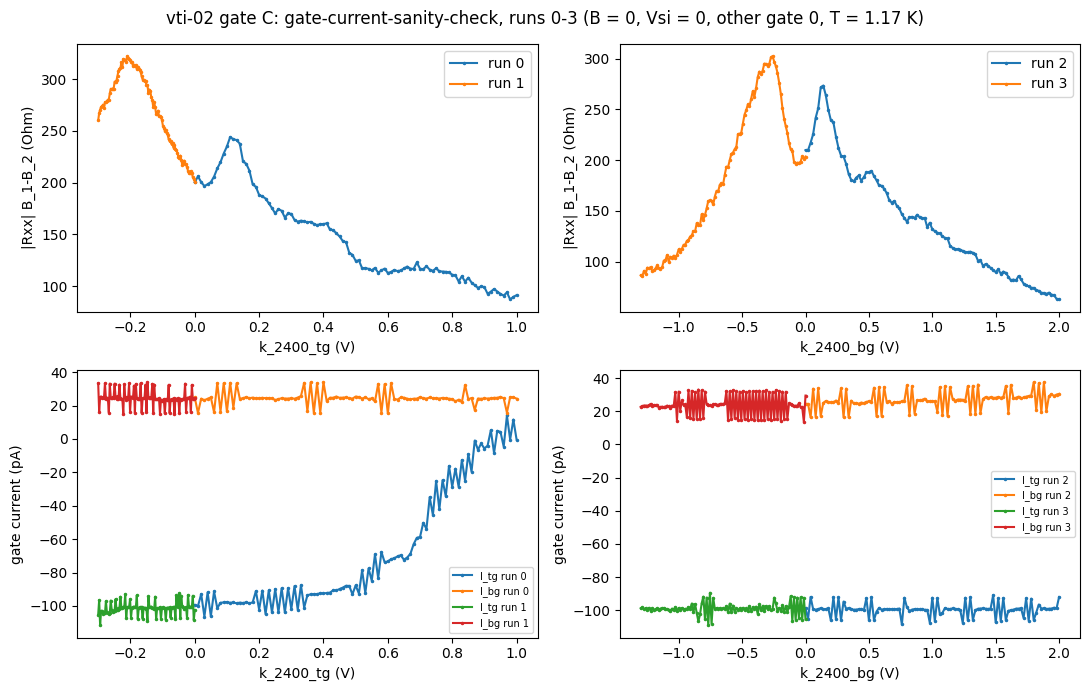

In [3]:
# Gate C — runs 0-3 (gate-current-sanity-check). Raw first: R = (sr1_X/gain)/I_drain per point, gate currents.
from hera.analysis import resolve_channels
fig, ax = plt.subplots(2, 2, figsize=(11, 7))
peaks = {}
for i in range(4):
    r = run(i)
    ch = {c.cid: c for c in resolve_channels(r.meta)}
    V = r.col(r.swept_axis)
    I = r.col("sr0_X") / ch["sr0"].gain
    R = np.abs((r.col("sr1_X") / ch["sr1"].gain) / I)
    i_tg, i_bg = r.col("k_2400_tg_curr"), r.col("k_2400_bg_curr")
    gate = r.swept_axis.replace("_volt", "")
    k = np.argmax(R); peaks[i] = (gate, V[k], R[k])
    print(f"run {i} {gate} {V[0]:+.2f}->{V[-1]:+.2f} V: R {R.min():.0f}-{R.max():.0f} Ohm (max at {V[k]:+.3f} V), "
          f"I_drain {I.min()*1e9:.2f}-{I.max()*1e9:.2f} nA, I_tg {i_tg.min()*1e12:+.0f}..{i_tg.max()*1e12:+.0f} pA, "
          f"I_bg {i_bg.min()*1e12:+.0f}..{i_bg.max()*1e12:+.0f} pA, T {r.col('T_sample').mean():.3f} K, interrupted={r.interrupted}")
    a = ax[0, 0] if "tg" in gate else ax[0, 1]
    a.plot(V, R, ".-", ms=3, label=f"run {i}"); a.set_xlabel(gate + " (V)"); a.set_ylabel("|Rxx| B_1-B_2 (Ohm)"); a.legend()
    b = ax[1, 0] if "tg" in gate else ax[1, 1]
    b.plot(V, i_tg * 1e12, ".-", ms=3, label=f"I_tg run {i}"); b.plot(V, i_bg * 1e12, ".-", ms=3, label=f"I_bg run {i}")
    b.set_xlabel(gate + " (V)"); b.set_ylabel("gate current (pA)"); b.legend(fontsize=7)
fig.suptitle("vti-02 gate C: gate-current-sanity-check, runs 0-3 (B = 0, Vsi = 0, other gate 0, T = 1.17 K)")
fig.tight_layout(); plt.show()


## Run 5 — 0 T gatemap (`gatemap`) → `cnp-and-dline-calibration`

Raw map (log R, TG fast [−0.3, +1.0] × BG slow [−1.3, +1.2], 20 × 40 mV, sr1 100 µV; run 4 was the same map aborted at 3 min when the ridge railed at 2 kΩ). **Read:** one dominant CNP ridge (A) running from (V_tg, V_bg) ≈ (+1.0, −1.3) to (−0.3, +0.45), plus a fainter **parallel** ridge (B) ≈ 0.19 V lower in V_tg — the second peak of runs 0–3. Ridge A's resistance is 240 Ω near D ≈ 0 and grows to ~2.4 kΩ at raw D ≈ +0.25 V/nm (saturating beyond), i.e. a D-tunable gap; **not a stacking read** (investigation Step 1 addendum: three candidate parents). Fits (ridge position = V_tg vs V_bg rows, so −slope = c_bg/c_tg): ridge A in the operating window |V_bg| < 0.5: slope −0.773 (rms 19 mV); high-D rows: −0.763 (rms 6 mV); ridge B: −0.69 (8 rows, rms 13 mV). **Calibration:** ratio c_bg/c_tg = 0.773 (data-calibrated; prior 0.864, −11 % — plausible hBN-thickness error, not a transposition); c_tg anchored at the 9.5 nm prior (absolute scale = geometry prior, pending a lever-arm check); n_offset = −0.089×10¹²; **D_offset from the R_CNP(D) symmetry** (vertex of the ridge-A resistance minimum, ≈ +0.012 raw) — the one feature that physically locates D = 0. Region B is electron-doped by 0.43×10¹² relative to A: a series-mosaic confound (same template expected, 13 % higher n at the fan density — extra tones at ×1.13). Realized D = 0 window inside the validators: **n = −1.27 … +3.27×10¹²** (TG-limited on both ends). Channel arithmetic: R = (sr1_X/1)/(sr0_X/−1e6).


run 5: 63 rows x 66; R 50-3068 Ohm; prior c_bg/c_tg = 0.864
--- ridge A (main) ---
A all rows: 29/30 rows, Vbg [-2.00,+2.00]: Vtg = -0.7308 Vbg +0.0474; c_bg/c_tg = 0.731; rms 15.5 mV
A high-D rows: 16/16 rows, Vbg [-2.00,-0.60]: Vtg = -0.7630 Vbg +0.0129; c_bg/c_tg = 0.763; rms 5.6 mV
A operating window |Vbg|<0.5: 12/12 rows, Vbg [-0.50,+0.50]: Vtg = -0.7728 Vbg +0.0512; c_bg/c_tg = 0.773; rms 19.2 mV
--- ridge B (parallel, lower Vtg) ---
B all rows: 8/8 rows, Vbg [-2.00,+2.00]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV
B operating window: 8/8 rows, Vbg [-0.50,+0.50]: Vtg = -0.6909 Vbg -0.1910; c_bg/c_tg = 0.691; rms 13.0 mV

CALIBRATION (ridge A, operating window): ratio 0.773 (prior 0.864, -11%), c_tg 2.796e-03 F/m2 (prior anchor), c_bg 2.161e-03; n_offset -0.0894e12; closure max|n| on fitted line 0.000e12
ridge B density offset relative to A: n_B = -0.426e12 (std 0.026), i.e. region B is electron-doped vs A by 0.43e12
D = 0 line (region A) realized n-window inside v

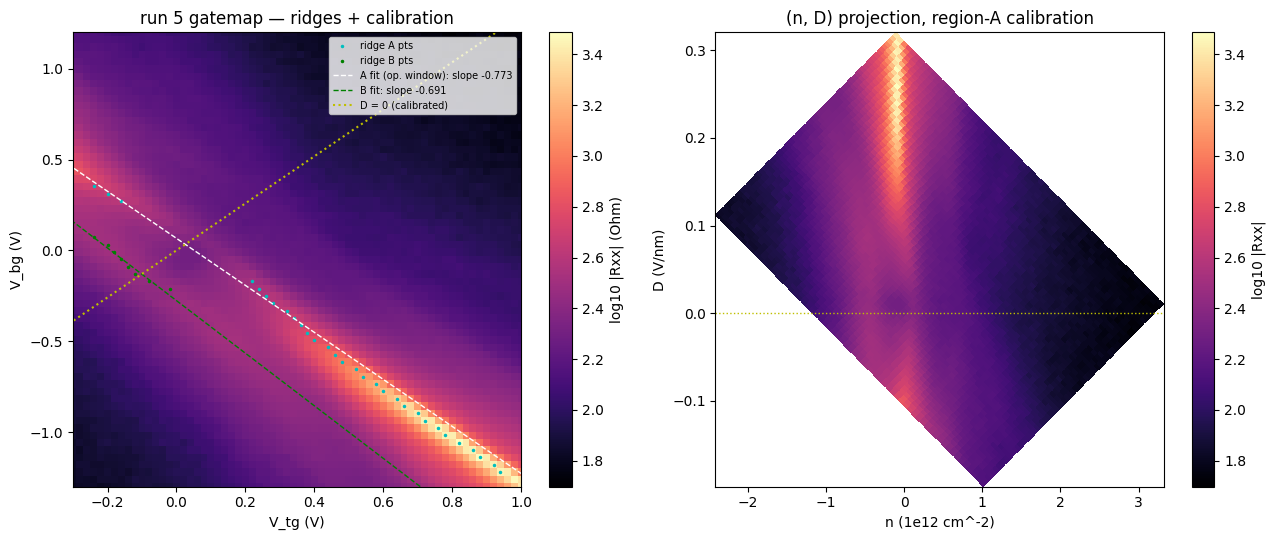

R_CNP(D) minimum: 297 Ohm at raw D = +0.048; parabola vertex raw D = +0.0130 V/nm -> D_offset = -0.0130


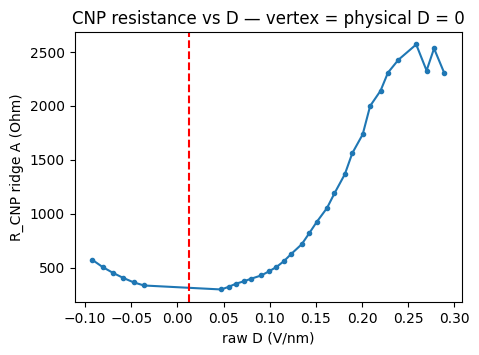

In [4]:
"""cnp-and-dline-calibration on gatemap run 5: per-row ridge extraction (two ridges), ratio fit on the
operating window near D = 0, offsets, closure check, realized D = 0 n-window; writes cal params to JSON."""
import json
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from sharpelab_nb.gates import stack_capacitance, calc_nD, calc_gate_voltages

rid = 5
g = fan_grids(str(Path(file_path) / str(rid))); rg = resistance_grids(g)
R = np.abs(rg.R["sr1"]); Vbg = g.slow
fs = g.meta["fast_setpoints"]; Vtg = np.asarray(fs[0] if isinstance(fs[0], list) else fs)
c_tg0 = stack_capacitance([(9.5, 3)]); c_bg0 = stack_capacitance([(11, 3)])
print(f"run {rid}: {g.nrows} rows x {g.nfast}; R {R.min():.0f}-{R.max():.0f} Ohm; prior c_bg/c_tg = {c_bg0/c_tg0:.3f}")

# ridge extraction: per row, up to two peaks; track continuity from the high-|D| end where ridge A is unambiguous
pts = []   # (Vbg, Vtg, R, ridge)
for i in range(g.nrows):
    r = gaussian_filter1d(R[i], 1.0)
    pk, _ = find_peaks(r, prominence=0.05 * (r.max() - r.min()) + 5)
    pk = [p for p in pk if 1 < p < g.nfast - 2]
    for p in sorted(pk, key=lambda p: -r[p])[:2]:
        pts.append((Vbg[i], Vtg[p], r[p]))
pts = np.array(pts)
# assign to ridges by distance to the high-D fit of ridge A (rows Vbg < -0.6), then refit each
selA = pts[:, 0] < -0.6
cfA0 = np.polyfit(pts[selA, 0], pts[selA, 1], 1)
dist = pts[:, 1] - np.polyval(cfA0, pts[:, 0])
ridgeA = pts[np.abs(dist) < 0.08]; ridgeB = pts[(dist < -0.08) & (dist > -0.45)]

def fit(p, lo, hi, label):
    m = (p[:, 0] >= lo) & (p[:, 0] <= hi)
    x, y = p[m, 0], p[m, 1]
    if len(x) < 4: print(f"{label}: {len(x)} rows, skip"); return None
    keep = np.ones(len(x), bool)
    for _ in range(3):
        cf = np.polyfit(x[keep], y[keep], 1); res = y - np.polyval(cf, x)
        keep = np.abs(res) < 2.5 * max(np.std(res[keep]), 0.01)
    cf = np.polyfit(x[keep], y[keep], 1); res = (y - np.polyval(cf, x))[keep]
    print(f"{label}: {keep.sum()}/{len(x)} rows, Vbg [{lo:+.2f},{hi:+.2f}]: Vtg = {cf[0]:+.4f} Vbg {cf[1]:+.4f}; "
          f"c_bg/c_tg = {-cf[0]:.3f}; rms {np.std(res)*1e3:.1f} mV")
    return cf

print("--- ridge A (main) ---")
cfA_all = fit(ridgeA, -2, 2, "A all rows")
cfA_hiD = fit(ridgeA, -2, -0.6, "A high-D rows")
cfA_op = fit(ridgeA, -0.5, 0.5, "A operating window |Vbg|<0.5")
print("--- ridge B (parallel, lower Vtg) ---")
cfB_all = fit(ridgeB, -2, 2, "B all rows")
cfB_op = fit(ridgeB, -0.5, 0.5, "B operating window")

# calibration: anchor c_tg at the prior (single hBN dielectric, better constrained), set c_bg from the operating-window ratio
cf = cfA_op if cfA_op is not None else cfA_all
ratio = -cf[0]; c_tg = c_tg0; c_bg = ratio * c_tg
n0, _ = calc_nD(cf[1], 0.0, c_tg, c_bg); n_offset = -n0
nA_ridge = calc_nD(np.polyval(cf, ridgeA[:, 0]), ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[0]
print(f"\nCALIBRATION (ridge A, operating window): ratio {ratio:.3f} (prior {c_bg0/c_tg0:.3f}, {100*(ratio/(c_bg0/c_tg0)-1):+.0f}%), "
      f"c_tg {c_tg:.3e} F/m2 (prior anchor), c_bg {c_bg:.3e}; n_offset {n_offset:+.4f}e12; closure max|n| on fitted line {np.abs(nA_ridge).max():.3f}e12")
nB = calc_nD(ridgeB[:, 1], ridgeB[:, 0], c_tg, c_bg, n_offset=n_offset)[0] if len(ridgeB) else np.array([np.nan])
print(f"ridge B density offset relative to A: n_B = {np.nanmedian(nB):+.3f}e12 (std {np.nanstd(nB):.3f}), i.e. region B is {'hole' if np.nanmedian(nB)>0 else 'electron'}-doped vs A by {abs(np.nanmedian(nB)):.2f}e12")
# D = 0 line of region A: V_tg = (c_bg/c_tg) V_bg + V_tg0 where n=0 at ... use calc_gate_voltages
ns = np.linspace(-1.5, 4.5, 601); Vt, Vb = calc_gate_voltages(ns, np.zeros_like(ns), c_tg, c_bg, n_offset=n_offset)
ok = (Vt >= -0.3) & (Vt <= 1.0) & (Vb >= -1.3) & (Vb <= 2.0)
print(f"D = 0 line (region A) realized n-window inside validators: {ns[ok].min():+.2f} .. {ns[ok].max():+.2f} e12; "
      f"CNP at (Vtg, Vbg) = ({calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[0]:+.3f}, {calc_gate_voltages(0,0,c_tg,c_bg,n_offset=n_offset)[1]:+.3f})")
# D range along ridge A
DA = calc_nD(ridgeA[:, 1], ridgeA[:, 0], c_tg, c_bg, n_offset=n_offset)[1]
print(f"ridge A spans D = {DA.min():+.3f} .. {DA.max():+.3f} V/nm; peak R vs D: " +
      ", ".join(f"{d:+.2f}:{r:.0f}" for d, r in sorted(zip(np.round(DA, 2), ridgeA[:, 2]))[::6]))
json.dump({"run": rid, "ratio": ratio, "c_tg": c_tg, "c_bg": c_bg, "n_offset": n_offset, "D_offset": float(-D0_raw) if "D0_raw" in globals() else 0.0,
           "slope": cf[0], "intercept": cf[1], "window": "A |Vbg|<0.5", "nB_offset": float(np.nanmedian(nB))},
          open(Path(file_path).parent / "hera_scratch" / "cal_run5.json", "w"), indent=1)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
m = ax[0].pcolormesh(Vtg, Vbg, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m, ax=ax[0], label="log10 |Rxx| (Ohm)")
ax[0].plot(ridgeA[:, 1], ridgeA[:, 0], "c.", ms=3, label="ridge A pts"); ax[0].plot(ridgeB[:, 1], ridgeB[:, 0], "g.", ms=3, label="ridge B pts")
xx = np.array([Vbg.min(), Vbg.max()])
ax[0].plot(np.polyval(cf, xx), xx, "w--", lw=1, label=f"A fit (op. window): slope {cf[0]:+.3f}")
if cfB_all is not None: ax[0].plot(np.polyval(cfB_all, xx), xx, "g--", lw=1, label=f"B fit: slope {cfB_all[0]:+.3f}")
ax[0].plot(Vt[ok], Vb[ok], "y:", lw=1.5, label="D = 0 (calibrated)")
ax[0].set_xlim(Vtg.min(), Vtg.max()); ax[0].set_ylim(Vbg.min(), Vbg.max()); ax[0].set_xlabel("V_tg (V)"); ax[0].set_ylabel("V_bg (V)")
ax[0].legend(fontsize=7, loc="upper right"); ax[0].set_title(f"run {rid} gatemap — ridges + calibration")
# (n, D) projection
N, D = calc_nD(Vtg[None, :], Vbg[:, None], c_tg, c_bg, n_offset=n_offset)
m2 = ax[1].pcolormesh(N, D, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(m2, ax=ax[1], label="log10 |Rxx|")
ax[1].axhline(0, color="y", ls=":", lw=1); ax[1].set_xlabel("n (1e12 cm^-2)"); ax[1].set_ylabel("D (V/nm)"); ax[1].set_title("(n, D) projection, region-A calibration")
fig.tight_layout(); plt.show()

# D_offset from the CNP-resistance symmetry in ±D (ridge A only, n within 0.1e12 of the fit line)
rows = []
for i in range(g.nrows):
    vc = cf[0] * Vbg[i] + cf[1]
    if vc < Vtg.min() + 0.03 or vc > Vtg.max() - 0.03: continue
    msk = np.abs(Vtg - vc) < 0.12
    r = gaussian_filter1d(R[i], 1.0); j = np.argmax(np.where(msk, r, -1))
    n_j, D_j = calc_nD(Vtg[j], Vbg[i], c_tg, c_bg, n_offset=n_offset)
    if abs(n_j) < 0.1: rows.append((D_j, r[j]))
rows = np.array(sorted(rows)); k = np.argmin(rows[:, 1]); sel = np.abs(rows[:, 0] - rows[k, 0]) < 0.12
cq = np.polyfit(rows[sel, 0], rows[sel, 1], 2); D0_raw = -cq[1] / (2 * cq[0])
print(f"R_CNP(D) minimum: {rows[k,1]:.0f} Ohm at raw D = {rows[k,0]:+.3f}; parabola vertex raw D = {D0_raw:+.4f} V/nm -> D_offset = {-D0_raw:+.4f}")
plt.figure(figsize=(5, 3.5)); plt.plot(rows[:, 0], rows[:, 1], "o-", ms=3); plt.axvline(D0_raw, color="r", ls="--")
plt.xlabel("raw D (V/nm)"); plt.ylabel("R_CNP ridge A (Ohm)"); plt.title("CNP resistance vs D — vertex = physical D = 0"); plt.show()


## Run 6 — SdH spot check, electron side: n = +3.2×10¹² (region-A cal), D = 0, B 0 → 10 T, 921 pts, T = 1.17 K

**Raw:** R = X/I of the B_1−B_2 pair falls 52 → 12 Ω by 0.5 T (a ρxy admixture — the pair straddles a flake corner; the n-side sign of the Hall term cancels part of ρxx), oscillates from ~1 T, grows to ±50 Ω by 5 T and enters the QH regime above 7.5 T (R → 530 Ω). Deep ρxx minima at 4.25, 6.0, 7.2 T (+ a shallow one at 4.95) sit at ν = 28, 20, 16 (24) for a *summed* frequency F_tot = 29.3 T — 1/B-periodic with period 1/29.3, alternate minima deep/shallow.

**FFT (SdH window [1, 5.5] T, δF 1.2 T, deg-5 background in B):** **7.3 T** (strongest, onset ≤ 0.5 T — censored at the record edge), **14.7** (0.61), **22.0** (0.62, onset 1.4 T), **29.3** (0.51, onset 1.9 T); 2.4 T is the detrend residual. Stable under bg degree 3/5/7 and both half-windows. F_L(g = 4) = 33.1 T at the geometry-prior scale.

**Read (Step 3, provisional — tone set at one density):** the pair **7.3 + 22.0 = 29.3 T** closes the Luttinger sum at a single global scale **0.886** (inside the 0.8–1.2 lever-arm prior); partition **0.25 / 0.75** vs the ABAB model's 0.23 / 0.77 at this n; the lighter pocket has the earlier onset (≤ 0.5 T vs 1.4 T), as LK ordering by mass requires. 14.7 = 2 × 7.3: a harmonic of the light tone (the light pocket is at ν ≈ 6 by 5 T, deeply non-sinusoidal); dropping it does not break the sum, so the Luttinger-aware screen allows it. **29.3 T is the F_L-tone whose origin must be discriminated** (breakdown/intermodulation sum of the pair — symmetry-allowed in ABAB — vs an ABCA domain): the B-window split here is weak (the high-B half has δF = 4.5 T), so it falls to (1) the fan's n-tracking (a sum tone tracks f₁ + f₂ exactly; an ABCA domain at region-B density would sit at 33 T, not 29) and (2) the LK masses (sum orbit m ≈ m₁ + m₂ ≈ 0.09 vs ABCA 0.074 vs heavy ABAB 0.061). Adjacent-N: a trilayer ML+BL pair would partition ≈ 0.13 / 0.87 — not this. **Provisional: ABAB (consistent-with → strong pending the fan's F(n) and the F_L-origin test).** Onset for the fan: light tone censored at 0.5 T (lower bound), heavy 1.4 T → B_lo = 1.0 T keeps the row count at 101 for 1/3-Nyquist; rows below 1 T would buy only the light tone's low-n periods, which the recipe already flags as unresolvable there.


run 6
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    electron side: n = +3.20e12 cm^-2, D = +0.00 V/nm; (Vtg, Vbg) = (+0.9836, +1.1661); B 0 -> 10 T uniform-B (50 mT to 1 T, 10 mT above); cal run 5: ratio 0.773, n_offset -0.089e12, D_offset -0.013
  rows:    921 of 921 (complete)
  swept:   magnet_field 0 → 10 (monotonic)
R -32.9..529.6 Ohm; T 1.165-1.292 K (Cernox MR shifts it); I_drain 9.84-9.94 nA
F_L(n = 3.2e12, g = 4) = 33.1 T
sdh_onset: onset_b = 0.50 T (tone 7.2 T) over B [0.50, 10.00] T
  tone    7.2 T: onset  0.50 T  dF  0.53 T  snr_max   74.1  [censored@edge, 2x->14.1T, 3x->22.2T, 4x->29.5T]
  tone   22.2 T: onset  1.42 T  dF  1.65 T  snr_max   59.7  [revives-below-gap, ~3x7.2T]
  tone   14.1 T: onset  1.86 T  dF  2.29 T  snr_max   42.3  [revives-below-gap, ~2x7.2T]
  tone   31.4 T: onset  1.89 T  dF  2.33 T  snr_max  137.6  [revives-below-gap, ~10x3.0T]
  tone   29.5 T: onset  1.85 T  dF  2.27 T  snr_max  182.3  [~4x7.2T]
  tone    3.0 T: onset  0.50 T  dF  0.53 T 

C:\Users\DGG\AppData\Local\Temp\ipykernel_10196\30953319.py:8: UserWarning: sdh_onset: tone 7.2 T is above threshold through the lowest window — oscillations persist to the record's low edge; onset_b = 0.50 T is the record edge, not a measured die-off
  on = sdh_onset(R, B, b_lo=0.5, r_full_scale=50e-6 / 10e-9); print(on.summary())


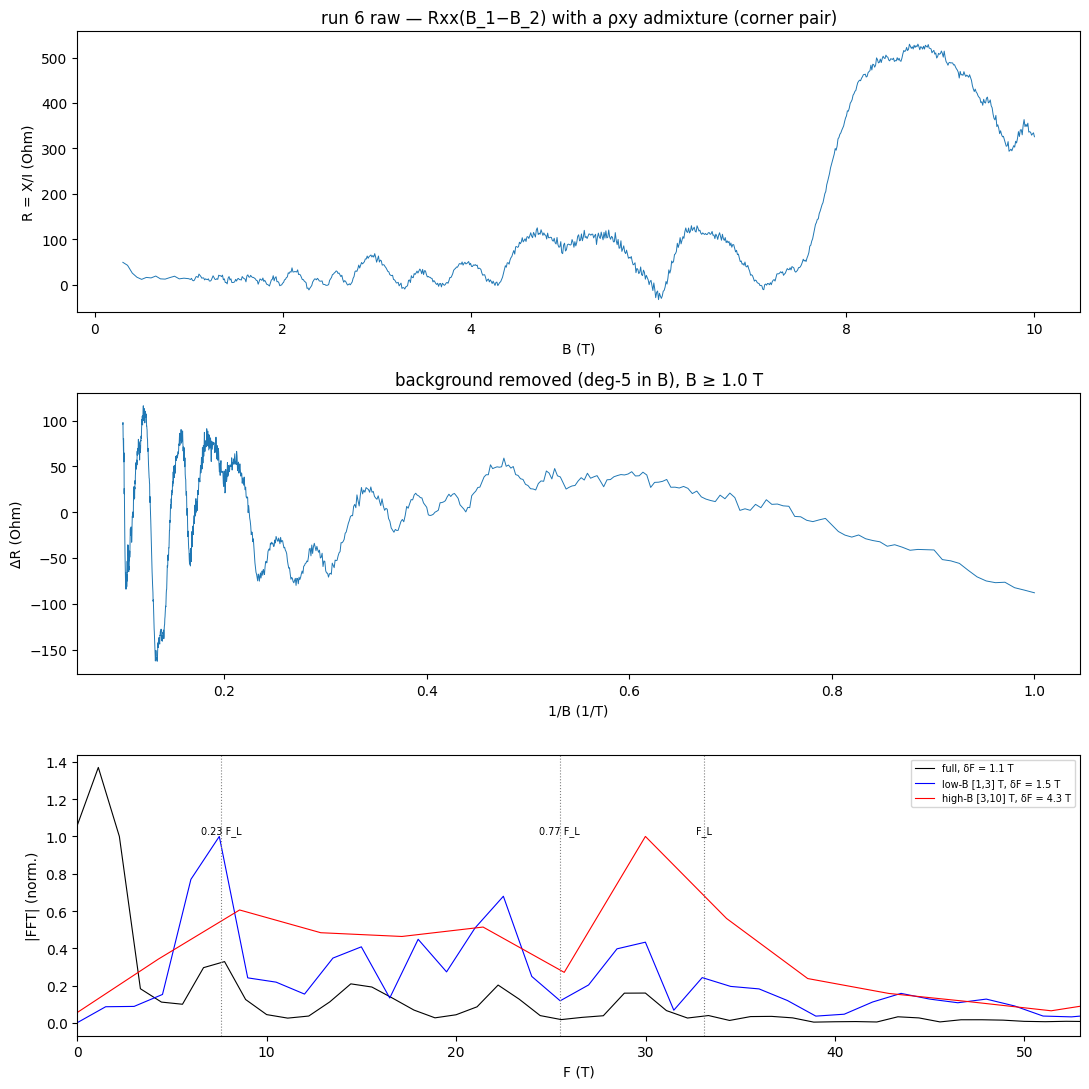

pair sum check: candidates [np.float64(7.8), np.float64(14.4), np.float64(22.2), np.float64(30.0)]


In [5]:
# Run 6 — SdH spot check, electron side, n = +3.2e12 at D = 0, B 0 -> 10 T. Raw first, then onset + FFT vs F_L.
from hera.analysis import resolve_channels, sdh_onset, SdhOnsetError
r = run(6); ch = {c.cid: c for c in resolve_channels(r.meta)}
B = r.col("magnet_field"); I = r.col("sr0_X") / ch["sr0"].gain; R = (r.col("sr1_X") / ch["sr1"].gain) / I; T = r.col("T_sample")
print(summarize_run(r)); print(f"R {R.min():.1f}..{R.max():.1f} Ohm; T {T.min():.3f}-{T.max():.3f} K (Cernox MR shifts it); I_drain {I.min()*1e9:.2f}-{I.max()*1e9:.2f} nA")
n12 = 3.2; FL = luttinger_frequency(n12 * 1e16); print(f"F_L(n = {n12}e12, g = 4) = {FL:.1f} T")
m = B >= 0.3; B, R = B[m], R[m]
on = sdh_onset(R, B, b_lo=0.5, r_full_scale=50e-6 / 10e-9); print(on.summary())
lo = 1.0
fig, ax = plt.subplots(3, 1, figsize=(11, 11))
ax[0].plot(B, R, lw=0.7); ax[0].set_xlabel("B (T)"); ax[0].set_ylabel("R = X/I (Ohm)"); ax[0].set_title("run 6 raw — Rxx(B_1−B_2) with a ρxy admixture (corner pair)")
sel = B >= lo; cf = np.polyfit(B[sel], R[sel], 5); dR = R[sel] - np.polyval(cf, B[sel])
ax[1].plot(1 / B[sel], dR, lw=0.7); ax[1].set_xlabel("1/B (1/T)"); ax[1].set_ylabel("ΔR (Ohm)"); ax[1].set_title(f"background removed (deg-5 in B), B ≥ {lo} T")
peaks = {}
for (blo, bhi, lab, c) in [(lo, B.max(), "full", "k"), (lo, 3.0, "low-B [1,3] T", "b"), (3.0, B.max(), "high-B [3,10] T", "r")]:
    f, spec = sdh_fft(R[:, None], B, b_range=(blo, bhi), bg_degree=5, log=False, nfft=4096)
    s = spec[0] / spec[0][f > 2].max(); ax[2].plot(f, s, c, lw=0.8, label=f"{lab}, δF = {1/(1/blo-1/bhi):.1f} T")
    pk = [(f[i], s[i]) for i in range(2, len(f) - 1) if s[i] > s[i-1] and s[i] > s[i+1] and s[i] > 0.12 and f[i] > 2]
    peaks[lab] = pk; print(f"FFT {lab} [{blo:.1f},{bhi:.1f}] T (δF {1/(1/blo-1/bhi):.2f} T): " + ", ".join(f"{a:.1f} T ({b:.2f})" for a, b in pk[:10]))
for frac, lab in [(1, "F_L"), (0.77, "0.77 F_L"), (0.23, "0.23 F_L")]:
    ax[2].axvline(frac * FL, color="gray", ls=":", lw=0.8); ax[2].text(frac * FL, 1.02, lab, fontsize=7, ha="center")
ax[2].set_xlim(0, 1.6 * FL); ax[2].set_xlabel("F (T)"); ax[2].set_ylabel("|FFT| (norm.)"); ax[2].legend(fontsize=7)
fig.tight_layout(); plt.show()
# Luttinger check on the resolved pair
fp = sorted(peaks["full"], key=lambda p: -p[1])
print("pair sum check: candidates", [round(a, 1) for a, _ in fp[:6]])


## Run 7 — SdH spot check, hole side: n_cal = −1.2×10¹² (D = 0), 10 → 0.3 T ride-down

**Raw:** R(B) is a low-density trace — broad non-sinusoidal features (peak 330 Ω at 2.45 T, near-zero minima at 1.7 and 2.05 T), then the fully symmetry-broken integer-QH ladder above ~5 T (minima at 5.0, 6.0, 6.95, 8.3 T), R → 590 Ω at 10 T. **FFT [1, 5] T (δF 1.25 T, only 4–6 periods):** one broad peak at 7.5 T with low-frequency weight at 2.5–4.4 T (scratch windows resolve ~4.4 and 6.8 and a weak 12.3). **Read:** the content sits at and below F_L × 0.886 = 11.0 T — 4.4 + 6.8 ≈ 11.2 would be a close, balanced pair summing to the full density (the ABAB near-CNP semimetal template; model at n_true = −1.06: 4.4 / 5.9 T), but the record cannot separate the two tones cleanly; an ABCA hole pocket here (m* ≈ 1 mₑ) would be LK-dead at T_e ≈ 8 K, so its absence is not evidence. **Weight: consistent-with ABAB, uninformative against ABCA** (resolution- and temperature-limited, as priced). **Lever-arm by-product:** the integer-ladder 1/B spacings above 4.5 T (0.0215–0.025 T⁻¹ per filling step, one 1.5-step outlier) give n·h/e ≈ 40–46 T → n = 0.97–1.1×10¹² at this gate point vs n_cal = 1.20 — an independent density scale of **0.80–0.92**, bracketing the electron-side Luttinger scale 0.886 from run 6. The geometry-prior capacitances are ~12 % high; one global scale serves both sides.


run 7
  type:    1D sweep
  recipe:  sdh-spot-check
  tags:    hole side: n = -1.20e12 cm^-2, D = +0.00 V/nm; (Vtg, Vbg) = (-0.2770, -0.4650); B 10 -> 0.3 T uniform-B 20 mT (ride-down); cal run 5: ratio 0.773, n_offset -0.089e12, D_offset -0.013
  rows:    486 of 486 (complete)
  swept:   magnet_field 10 → 0.3 (monotonic)
R -0.4..586.9 Ohm
F_L(n_cal = 1.2e12) = 12.4 T; at scale 0.886: 11.0 T
FFT SdH window [1,5] T: 2.5 T (0.79), 7.5 T (1.00), 15.0 T (0.28)
FFT [1,3] T: 3.0 T (0.89), 7.5 T (1.00)


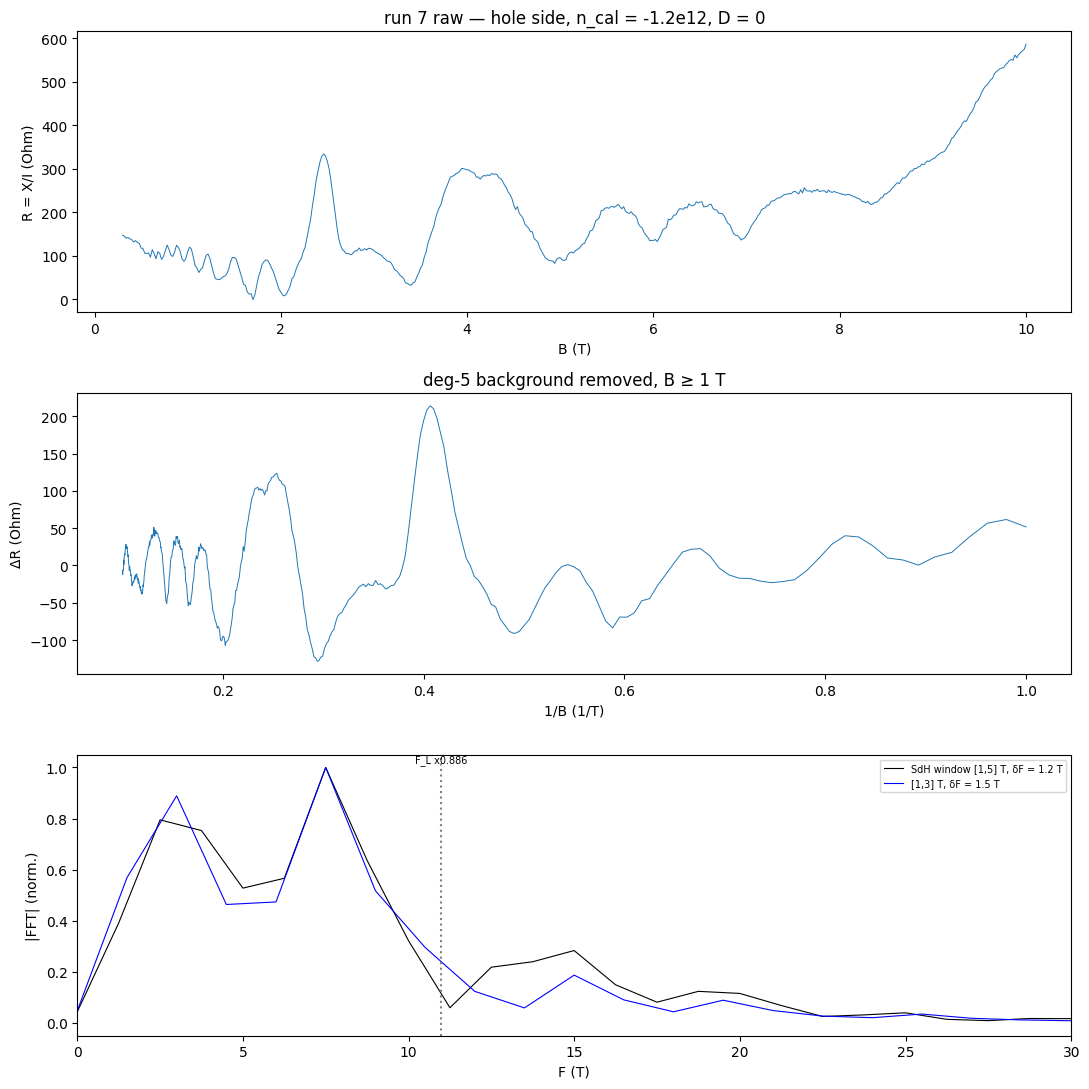

rho_xx minima above 4.5 T at B = [4.94 6.04 6.94 8.4 ] T; consecutive 1/B spacings: [0.025  0.0215 0.0369]
median spacing 0.0250 1/T per filling step -> n h/e = 39.9 T -> n = 0.97e12 if Δν = 1 (lever-arm scale vs n_cal 1.2: 0.804)


In [6]:
# Run 7 — SdH spot check, hole side: n_cal = -1.2e12 (D = 0), B 10 -> 0.3 T ride-down, 486 pts. Raw first.
from hera.analysis import resolve_channels, sdh_onset
r = run(7); ch = {c.cid: c for c in resolve_channels(r.meta)}
B = r.col("magnet_field"); I = r.col("sr0_X") / ch["sr0"].gain; R = (r.col("sr1_X") / ch["sr1"].gain) / I
print(summarize_run(r)); print(f"R {R.min():.1f}..{R.max():.1f} Ohm")
o = np.argsort(B); B, R = B[o], R[o]
FLc = luttinger_frequency(1.2e16); print(f"F_L(n_cal = 1.2e12) = {FLc:.1f} T; at scale 0.886: {0.886*FLc:.1f} T")
fig, ax = plt.subplots(3, 1, figsize=(11, 11))
ax[0].plot(B, R, lw=0.7); ax[0].set_xlabel("B (T)"); ax[0].set_ylabel("R = X/I (Ohm)"); ax[0].set_title("run 7 raw — hole side, n_cal = -1.2e12, D = 0")
m = B >= 1.0; cf = np.polyfit(B[m], R[m], 5); dR = R[m] - np.polyval(cf, B[m])
ax[1].plot(1 / B[m], dR, lw=0.7); ax[1].set_xlabel("1/B (1/T)"); ax[1].set_ylabel("ΔR (Ohm)"); ax[1].set_title("deg-5 background removed, B ≥ 1 T")
for (blo, bhi, lab, c) in [(1.0, 5.0, "SdH window [1,5] T", "k"), (1.0, 3.0, "[1,3] T", "b")]:
    f, spec = sdh_fft(R[:, None], B, b_range=(blo, bhi), bg_degree=5, log=False, nfft=4096); s = spec[0] / spec[0][f > 2].max()
    ax[2].plot(f, s, c, lw=0.8, label=f"{lab}, δF = {1/(1/blo-1/bhi):.1f} T")
    pk = [(f[i], s[i]) for i in range(2, len(f) - 1) if s[i] > s[i-1] and s[i] > s[i+1] and s[i] > 0.2 and f[i] > 2]
    print(f"FFT {lab}: " + ", ".join(f"{a:.1f} T ({b:.2f})" for a, b in pk[:8]))
ax[2].axvline(0.886 * FLc, color="gray", ls=":"); ax[2].text(0.886 * FLc, 1.02, "F_L x0.886", fontsize=7, ha="center")
ax[2].set_xlim(0, 30); ax[2].set_xlabel("F (T)"); ax[2].set_ylabel("|FFT| (norm.)"); ax[2].legend(fontsize=7)
fig.tight_layout(); plt.show()
# integer-QH ladder at high B: minima of dR for B > 4.5 T -> 1/B spacing -> n h/e
m2 = B >= 4.5; cf2 = np.polyfit(B[m2], R[m2], 3); d2 = R[m2] - np.polyval(cf2, B[m2]); b2 = B[m2]
from scipy.signal import find_peaks
mins, _ = find_peaks(-d2, prominence=15); Bm = b2[mins]; inv = np.sort(1 / Bm)
print("rho_xx minima above 4.5 T at B =", np.round(Bm, 2), "T; consecutive 1/B spacings:", np.round(np.diff(inv), 4))
dnu = np.median(np.diff(inv)); print(f"median spacing {dnu:.4f} 1/T per filling step -> n h/e = {1/dnu:.1f} T -> n = {1/dnu/41.36:.2f}e12 if Δν = 1 (lever-arm scale vs n_cal 1.2: {1/dnu/41.36/1.2:.3f})")


## Run 8 — Landau fan, electron side, D = 0: n_cal 1.60 → 3.25×10¹² (61 pts) × B 1 → 10 T (101 rows uniform in 1/B), T ≈ 1.2 K

**Raw:** clean Landau-level rays across the whole window from 1 T; QH regime above ~7.5 T (R to ~1 kΩ, no rail at the 10 kΩ scale); no leakage, 6161/6161 points. **Per-column SdH FFT, [1, 6] T (δF 1.2 T), global density scale 0.886 from run 6 / run 7:** four tracks.
1. **Light branch** 3.0 → 7.5 T — rides the ABAB light-pocket F(n) curve (model 1.8 → 6.3 T; the low-n end sits ~1 T above the model, at the δF floor).
2. **Heavy branch** 13.9 → 22.1 T — rides the ABAB heavy-pocket curve (model 13 → 22.9 T).
3. **F_L track** 17.1 → 30.7 T = f_light + f_heavy column by column (e.g. 7.2 + 22.0 = 29.2 vs 28.5; 5.1 + 18.1 = 23.2 vs 22.8; 3.7 + 15.5 = 19.2 vs 18.9): **the Luttinger sum holds across density** — the pair carries the full g = 4 density at one scale.
4. **Difference track** 11–15 T, nearly n-flat = f_heavy − f_light at every column (22.0 − 7.2 = 14.8 ↔ 13.8–14.9; 15.5 − 3.7 = 11.8 ↔ 11.9): a combination tone that cannot be a pocket (its F(n) is flat/non-Onsager) — it fixes the mechanism that also makes the sum tone (intermodulation / quantum-interference orbits of the two pockets, symmetry-allowed in ABAB). The 2× light harmonic appears separately at high n (14.9–16 T).

**Overlays (Verify: forward model, dual overlay):** the two branches track the **ABAB** curves, not the trilayer ML+BL pair (whose partner would sit at 1–2 T and main branch at F_L — adjacent-N excluded by trajectory); partition f_light/F_L runs 0.20 → 0.25 over n_true 1.4 → 2.9 (model 0.12 → 0.22), both branches parabolic-shaped, no supra-linear Dirac-like branch (ABCB's signature not seen, resolvable here: a J = 1 partner would be a ≲ 0.1 F_L tone that would fall under the δF floor at low n, so "not seen" is weak there). **Degeneracy audit:** the g = 4 F_L at scale 0.886 is consistent with the hole-side integer-ladder density (scale 0.80–0.92) → no flavor polarization at the operating point. **Grid-change reproduction:** the same tone set appears in the uniform-B spot check (run 6) and the uniform-1/B fan columns. **Read:** two branches on the ABAB curves + Luttinger closure across n + combination-tone origin of the F_L tone established by its difference partner → **ABAB (strong)** for the B_1−B_2 region, pending the LK mass split (run 9+) as the independent check. Lever-arm: QH-regime minima spacing along n at 8–10 T (printed) cross-checks the scale.


run 8: 101 rows (B 1.00-10.00 T) x 61 n-pts (n 1.60-3.25e12, D +0.000..+0.000); R -33..979 Ohm


col  n_cal  n_true   peaks(T, norm)                      sum of top two fundamentals vs F_L
  0  3.25  2.88   7.5(1.00), 14.9(0.56), 22.1(0.57), 30.7(0.35)   F_L=29.8
  4  3.14  2.78   7.2(1.00), 13.8(0.42), 16.1(0.42), 22.0(0.61), 28.5(0.55)   F_L=28.5
  8  3.03  2.68   6.5(1.00), 15.2(0.29), 21.4(0.49), 27.5(0.41), 29.8(0.28)   F_L=27.9
 12  2.92  2.59   6.2(1.00), 14.8(0.26), 20.5(0.61), 26.5(0.52)   F_L=26.6
 16  2.81  2.49   5.8(1.00), 13.9(0.36), 20.2(0.52), 26.2(0.42), 27.8(0.41)   F_L=26.0
 20  2.70  2.39   5.5(1.00), 12.7(0.43), 19.5(0.66), 25.3(0.52)   F_L=24.7
 24  2.59  2.29   5.2(1.00), 13.4(0.66), 18.7(0.58), 24.0(0.60)   F_L=23.5
 28  2.48  2.20   5.1(1.00), 7.9(0.54), 13.2(0.66), 18.1(1.00), 22.8(0.97)   F_L=22.8
 32  2.37  2.10   4.8(1.00), 9.3(0.45), 13.0(0.73), 17.3(0.47), 21.9(0.51)   F_L=21.6
 36  2.26  2.00   4.4(1.00), 8.5(0.58), 12.6(0.59), 16.8(0.60), 21.2(0.48)   F_L=21.0
 40  2.15  1.90   4.0(1.00), 12.1(0.59), 15.9(0.65), 20.0(0.48)   F_L=19.7
 44  2.04  1.8

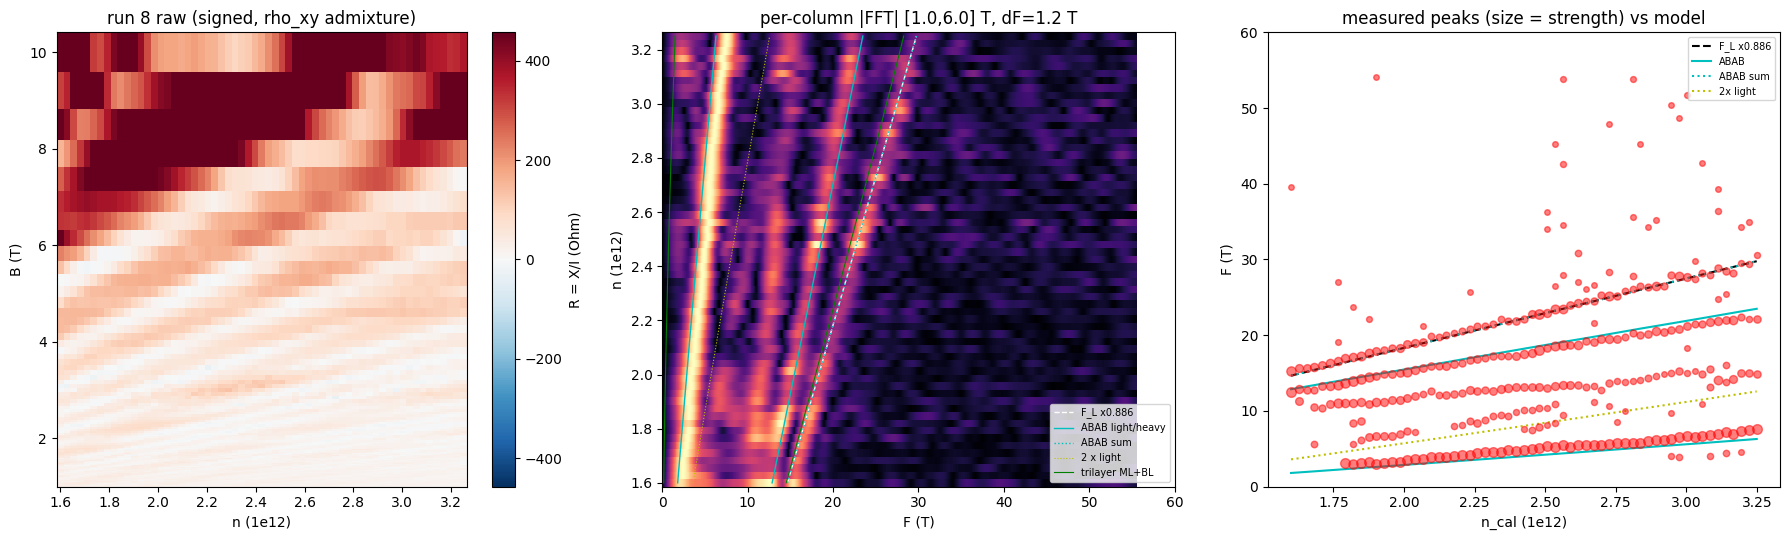

col  n_cal  light  heavy  sum(l+h)  top-track  F_L*scale   diff(h-l)  mid-track
  0  3.25     7.5   22.1     29.7      30.7      29.8       14.6      14.9
  6  3.08     6.8   21.7     28.5      27.9      28.3       14.9      15.5
 12  2.92     6.2   20.5     26.6      26.5      26.7       14.3      14.8
 18  2.75     5.7   19.5     25.2      25.2      25.2       13.8      14.0
 24  2.59     5.2   18.7     23.9      24.0      23.7       13.5      13.4
 30  2.42     4.9   17.6     22.5      22.2      22.2       12.7      12.9
 36  2.26     4.4   16.8     21.2      21.2      20.7       12.4      12.0
 42  2.09     3.9   16.0     19.8      19.9      19.2       12.1      11.1
 48  1.93     3.1   11.2     14.3      18.1      17.7        8.0       nan
 54  1.76     2.9   13.5     16.4      16.5      16.2       10.5       nan
 60  1.60     2.5   12.5     15.1      15.3      14.7       10.0       nan
B = 9.17 T: minima at n_cal = [1.85 2.86]; median spacing 1.017e12 -> scale = Δν·eB/h/Δn_cal = 

In [10]:
"""Fan read (partial or complete): re-form R(n, B), raw pcolormesh, per-column SdH FFT in 1/B, peak tracks F(n),
overlay ABAB / ABCA model curves under a global density scale; Luttinger sum per column."""
import sys, json
from sharpelab_nb.gates import calc_nD
sys.path.insert(0, r"C:\Users\DGG\measurement_env\hera\models\tetralayer_fs_count")
import fs_count_b0 as fsm

rid = 8; scale = 0.886   # global density scale pinned by the run-6 Luttinger sum (and the run-7 ladder)
cal = json.load(open(Path(file_path).parent / "hera_scratch" / "cal_run5.json"))
g = fan_grids(str(Path(file_path) / str(rid))); rg = resistance_grids(g); R = rg.R["sr1"]; B = g.slow
fs = g.meta["fast_setpoints"]; Vtg = np.asarray(fs[0]); Vbg = np.asarray(fs[1])
n12, D = calc_nD(Vtg, Vbg, cal["c_tg"], cal["c_bg"], cal["n_offset"], cal["D_offset"])
print(f"run {rid}: {g.nrows} rows (B {B.min():.2f}-{B.max():.2f} T) x {g.nfast} n-pts (n {n12.min():.2f}-{n12.max():.2f}e12, D {D.min():+.3f}..{D.max():+.3f}); R {np.nanmin(R):.0f}..{np.nanmax(R):.0f} Ohm")
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
m = ax[0].pcolormesh(n12, B, R, shading="nearest", cmap="RdBu_r", vmin=-np.percentile(np.abs(R), 98), vmax=np.percentile(np.abs(R), 98))
fig.colorbar(m, ax=ax[0], label="R = X/I (Ohm)"); ax[0].set_xlabel("n (1e12)"); ax[0].set_ylabel("B (T)"); ax[0].set_title(f"run {rid} raw (signed, rho_xy admixture)")
# per-column FFT
if g.nrows >= 12:
    lo, hi = B.min(), 6.0   # SdH window; above ~7 T the QH regime distorts the background fit
    f, spec = sdh_fft(R, B, b_range=(lo, hi), bg_degree=3 if g.nrows < 30 else 5, log=False, nfft=2048)
    spec = spec / spec[:, f > 2].max(axis=1, keepdims=True)
    m2 = ax[1].pcolormesh(f, n12, spec, shading="nearest", cmap="magma", vmin=0, vmax=1)
    ax[1].set_xlim(0, 60); ax[1].set_xlabel("F (T)"); ax[1].set_ylabel("n (1e12)"); ax[1].set_title(f"per-column |FFT| [{lo:.1f},{hi:.1f}] T, dF={1/(1/lo-1/hi):.1f} T")
    # model overlays: ABAB (light, heavy), ABCA singleton, trilayer for adjacent-N, vs n_true = scale * n_cal
    nn = np.linspace(max(n12.min(), 1.0), n12.max(), 25)
    FL = luttinger_frequency(scale * nn * 1e16)
    ab = np.array([[F for F, k in fsm.abab_fs(scale * x * 1e16)[1]][:2] for x in nn])
    tri = np.array([[F for F, k in fsm.bernal_fs(scale * x * 1e16, "ABA", fsm.ABA_TRI)[1]][:2] for x in nn]) if hasattr(fsm, "bernal_fs") else None
    ax[1].plot(FL, nn, "w--", lw=1, label=f"F_L x{scale}"); ax[1].plot(ab[:, 0], nn, "c-", lw=1, label="ABAB light/heavy"); ax[1].plot(ab[:, 1], nn, "c-", lw=1)
    ax[1].plot(ab.sum(axis=1), nn, "c:", lw=1, label="ABAB sum"); ax[1].plot(2 * ab[:, 0], nn, "y:", lw=0.8, label="2 x light")
    if tri is not None: ax[1].plot(tri[:, 0], nn, "g-", lw=0.8, label="trilayer ML+BL"); ax[1].plot(tri[:, 1], nn, "g-", lw=0.8)
    ax[1].legend(fontsize=7, loc="lower right")
    # peak tracks per column + Luttinger check
    print("col  n_cal  n_true   peaks(T, norm)                      sum of top two fundamentals vs F_L")
    tracks = []
    for j in range(0, g.nfast, max(1, g.nfast // 15)):
        s = spec[j]; pk = [(f[i], s[i]) for i in range(2, len(f) - 1) if s[i] > s[i-1] and s[i] > s[i+1] and s[i] > 0.25 and 3 < f[i] < 60]
        pk = sorted(pk, key=lambda p: -p[1])[:5]
        print(f"{j:3d}  {n12[j]:.2f}  {scale*n12[j]:.2f}   " + ", ".join(f"{a:.1f}({b:.2f})" for a, b in sorted(pk)) + f"   F_L={FL[np.argmin(abs(nn-n12[j]))]:.1f}")
        tracks.append((n12[j], pk))
    ax[2].plot(nn, FL, "k--", label=f"F_L x{scale}"); ax[2].plot(nn, ab[:, 0], "c-", label="ABAB"); ax[2].plot(nn, ab[:, 1], "c-"); ax[2].plot(nn, ab.sum(axis=1), "c:", label="ABAB sum"); ax[2].plot(nn, 2 * ab[:, 0], "y:", label="2x light")
    for j in range(g.nfast):
        s = spec[j]; pk = [(f[i], s[i]) for i in range(2, len(f) - 1) if s[i] > s[i-1] and s[i] > s[i+1] and s[i] > 0.25 and 3 < f[i] < 60]
        for a, b in pk: ax[2].plot(n12[j], a, "o", ms=3 + 4 * b, color="r", alpha=0.5)
    ax[2].set_xlabel("n_cal (1e12)"); ax[2].set_ylabel("F (T)"); ax[2].set_ylim(0, 60); ax[2].legend(fontsize=7); ax[2].set_title("measured peaks (size = strength) vs model")
fig.tight_layout(); plt.show()

# Luttinger sum per column on the three strongest tracks (light < 10 T, heavy 14-26 T, top 16-32 T) and the difference tone
print("col  n_cal  light  heavy  sum(l+h)  top-track  F_L*scale   diff(h-l)  mid-track")
for j in range(0, g.nfast, 6):
    s_ = spec[j]
    def pk_in(a, b):
        m_ = (f >= a) & (f <= b)
        return f[m_][np.argmax(s_[m_])] if (m_.sum() > 0 and s_[m_].max() > 0.2) else np.nan
    fl_ = luttinger_frequency(scale * n12[j] * 1e16)
    light = pk_in(2.5, 10); heavy = pk_in(0.6 * fl_, 0.88 * fl_); top = pk_in(0.9 * fl_, 1.12 * fl_); mid = pk_in(10.5, 0.58 * fl_)
    print(f"{j:3d}  {n12[j]:.2f}   {light:5.1f}  {heavy:5.1f}   {light+heavy:6.1f}    {top:6.1f}     {fl_:5.1f}      {heavy-light:5.1f}     {mid:5.1f}")

# Lever-arm check from the QH regime: rho_xx minima vs n along a high-B row; their spacing = Δν·(e/h)·B in true n
from scipy.signal import find_peaks
for Brow in (8.0, 9.0, 10.0):
    i = int(np.argmin(np.abs(B - Brow))); row = R[i]
    mins, _ = find_peaks(-row, prominence=0.1 * np.ptp(row)); nm = n12[mins]
    if len(nm) >= 2:
        d = np.median(np.diff(np.sort(nm))); eB_h = 2.418e10 * B[i] * 1e-12  # e/h in 1e12 cm^-2 per T
        print(f"B = {B[i]:.2f} T: minima at n_cal = {np.round(np.sort(nm), 2)}; median spacing {d:.3f}e12 -> scale = Δν·eB/h/Δn_cal = "
              + ", ".join(f"Δν={k}: {k*eB_h/d:.3f}" for k in (1, 2, 4)))


## Runs 9–14 — LK mass ladder (`temperature-dependence-vti` Flavor B): n = +3.2×10¹², D = 0, rungs 1.2 / 6.1 / 10.1 / 15.1 / 22.1 / 30.0 K, B [2, 7] T alternating

**Thermal record:** every rung hover-accepted (intra-sweep T spread ≤ 0.08 K); heaters off at end. **Per-tone FFT amplitudes vs T, LK fits on the heated rungs** (T_e = T there; the base rung is excluded — this rig's base T_e is uncertain — and its amplitudes sit on/near the fitted curves, implying T_e(base) ≲ 4 K, i.e. better than the rig card's ≈ 8 K figure):
- **light (5.6 T at δF 2.8): m\* = 0.028 ± 0.002 mₑ** — the ABAB light-pocket model value (0.028) exactly.
- **heavy (22.4 T): m\* = 0.041 ± 0.002** full window, 0.038 ± 0.002 in [2, 3.5] T, 0.057 ± 0.002 in [3.5, 7] T (where δF = 7 T mixes in the sum tone) — **window-dependent: reported as a fork (STYLE 14)**, robustly 0.04–0.06 vs the model's 0.061; ratio heavy/light 1.4–2.0 (model 2.2; φ² asymptote 2.6). Deciding measurement if the ratio must be pinned: a ladder over 1.5–10 T at 10 mT (δF 1.8 in each half-window), ~3 h/rung, or a lower-T_e rig.
- **2×light (14 T): m\* = 0.052–0.058 ≈ 2 m_light** — the harmonic assignment confirmed by mass.
- **F_L tone (28–30 T): m\* = 0.051–0.069**, heavier than the heavy branch, reaching m_l + m_h (0.07–0.09) in the high window — a combination orbit's mass, and clearly not bound to the ABCA singleton's 0.074 with two sub-F_L fundamentals coexisting. **Beat exclusion:** the light component (0.028) is *lighter* than the main branch — cannot be a beat: two genuine bands (decisive).
**Verify closed:** the LK mass split separates two real bands + one combination tone; together with the B-window split (sum/heavy 0.55 → 1.03, diff/light 0.27 → 1.6 with rising B, run 6) and the difference tone's non-Onsager trajectory (run 8), the F_L-tone origin discrimination **passes: combination/breakdown, not an ABCA domain**.


Task was destroyed but it is pending!
task: <Task pending name='Task-93' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-94' coro=<Kernel.shell_main() running at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>


C:\Users\DGG\AppData\Local\programs\python\python312\Lib\collections\__init__.py:449: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  result = tuple_new(cls, iterable)
Task was destroyed but it is pending!
task: <Task pending name='Task-94' coro=<Kernel.shell_main() running at C:\Users\DGG\measurement_env\.venv\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]>


run 9: T = 1.24 ± 0.02 K, window [2.0,7.0] T, light 5.6T:2e+04, 2xlight 14.0T:1.44e+04, heavy 22.4T:1.18e+04, sum 28.0T:1.14e+04
run 10: T = 6.13 ± 0.04 K, window [2.0,7.0] T, light 5.6T:1.65e+04, 2xlight 14.0T:1.16e+04, heavy 22.4T:9.31e+03, sum 28.0T:7.86e+03
run 11: T = 10.12 ± 0.02 K, window [2.0,7.0] T, light 5.6T:1.29e+04, 2xlight 14.0T:6.26e+03, heavy 22.4T:6.34e+03, sum 28.0T:4.42e+03
run 12: T = 15.12 ± 0.05 K, window [2.0,7.0] T, light 5.6T:8.86e+03, 2xlight 16.8T:3.12e+03, heavy 22.4T:3.48e+03, sum 28.0T:2.17e+03
run 13: T = 22.11 ± 0.08 K, window [2.0,7.0] T, light 5.6T:5.87e+03, 2xlight 14.0T:875, heavy 22.4T:1.66e+03, sum 30.8T:833
run 14: T = 30.04 ± 0.05 K, window [2.0,7.0] T, light 5.6T:3.05e+03, 2xlight 14.0T:849, heavy 19.6T:728, sum 30.8T:467
B_eff = 3.11 T
LK fit light (heated rungs, B_eff 3.11): m* = 0.0285 ± 0.0016 m_e; base-rung amplitude implies T_e = n/a
LK fit 2xlight (heated rungs, B_eff 3.11): m* = 0.0529 ± 0.0035 m_e; base-rung amplitude implies T_e = 3.6 

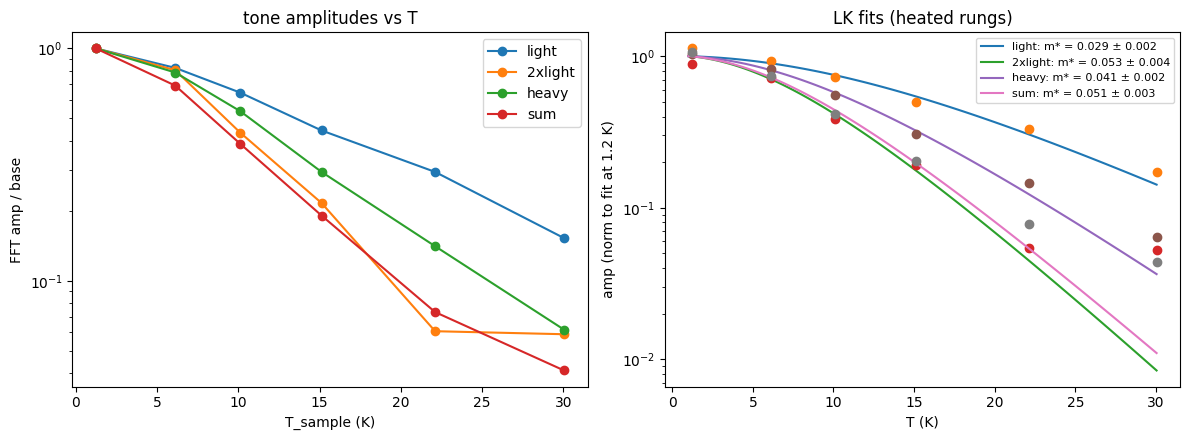


window-resolved LK (heated rungs):
  window [2.0,3.5] T (B_eff 2.55, dF 4.7 T): 2xlight m* = 0.076 ± 0.016, heavy m* = 0.038 ± 0.002, sum m* = 0.057 ± 0.006
  window [3.5,7.0] T (B_eff 4.67, dF 7.0 T): 2xlight m* = 0.058 ± 0.001, heavy m* = 0.057 ± 0.002, sum m* = 0.069 ± 0.007
  window [2.0,7.0] T (B_eff 3.11, dF 2.8 T): light m* = 0.028 ± 0.001, 2xlight m* = 0.052 ± 0.004, heavy m* = 0.041 ± 0.002, sum m* = 0.051 ± 0.003


In [11]:
"""LK ladder read: per-rung FFT amplitudes of the named tones vs T; fit X/sinh(X) per tone for m*."""
from scipy.optimize import curve_fit
from hera.analysis import resolve_channels

runs = [9, 10, 11, 12, 13, 14]   # LK ladder rungs: base, 6, 10, 15, 22, 30 K
TONES = {"light": (5.5, 9.5), "2xlight": (12.5, 17), "heavy": (19.5, 25), "sum": (27, 32)}
rows = []
for rid in runs:
    r = run(rid); ch = {c.cid: c for c in resolve_channels(r.meta)}
    B = r.col("magnet_field"); I = r.col("sr0_X") / ch["sr0"].gain; R = (r.col("sr1_X") / ch["sr1"].gain) / I; T = r.col("T_sample")
    o = np.argsort(B); B, R = B[o], R[o]
    lo, hi = max(B.min(), 2.0), min(B.max(), 7.0)
    f, spec = sdh_fft(R[:, None], B, b_range=(lo, hi), bg_degree=5, log=False, nfft=4096); s = spec[0]
    amps = {k: s[(f >= a) & (f <= b)].max() for k, (a, b) in TONES.items()}
    fpk = {k: f[(f >= a) & (f <= b)][np.argmax(s[(f >= a) & (f <= b)])] for k, (a, b) in TONES.items()}
    Tm = float(np.nanmean(T)); rows.append((rid, Tm, float(np.nanstd(T)), amps, fpk, lo, hi, r.tags))
    print(f"run {rid}: T = {Tm:.2f} ± {np.nanstd(T):.2f} K, window [{lo:.1f},{hi:.1f}] T, " + ", ".join(f"{k} {fpk[k]:.1f}T:{amps[k]:.3g}" for k in TONES))
B_eff = 1 / ((1 / rows[0][5] + 1 / rows[0][6]) / 2)
print(f"B_eff = {B_eff:.2f} T")
def lk(T, A, m):
    X = 14.69 * m * T / B_eff; return A * X / np.sinh(X)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
Ts = np.array([x[1] for x in rows])
for k in TONES:
    A = np.array([x[3][k] for x in rows]); ax[0].semilogy(Ts, A / A[0], "o-", label=k)
    try:
        sel = Ts > 3.0  # heated rungs only (base T_e unknown)
        if sel.sum() >= 3:
            p, cov = curve_fit(lk, Ts[sel], A[sel], p0=(A[sel][0] * 1.2, 0.05), bounds=([0, 0.005], [np.inf, 1.0]))
            Tfit = np.linspace(1, Ts.max(), 100); ax[1].semilogy(Tfit, lk(Tfit, *p) / lk(1.2, *p), "-", label=f"{k}: m* = {p[1]:.3f} ± {np.sqrt(cov[1,1]):.3f}")
            ax[1].semilogy(Ts, A / lk(1.2, *p), "o")
            print(f"LK fit {k} (heated rungs, B_eff {B_eff:.2f}): m* = {p[1]:.4f} ± {np.sqrt(cov[1,1]):.4f} m_e; base-rung amplitude implies T_e = "
                  + (f"{np.interp(A[0] / p[0], lk(np.linspace(30, 0.5, 500), 1, p[1])[::1], np.linspace(30, 0.5, 500)):.1f} K" if A[0] < p[0] else "n/a"))
    except Exception as e:
        print("fit", k, "failed:", e)
ax[0].set_xlabel("T_sample (K)"); ax[0].set_ylabel("FFT amp / base"); ax[0].legend(); ax[0].set_title("tone amplitudes vs T")
ax[1].set_xlabel("T (K)"); ax[1].set_ylabel("amp (norm to fit at 1.2 K)"); ax[1].legend(fontsize=8); ax[1].set_title("LK fits (heated rungs)")
fig.tight_layout(); plt.show()

# --- window-resolved LK for the heavy and sum tones (>= 3 periods per window): [2,3.5] and [3.5,7] T ---
print("\nwindow-resolved LK (heated rungs):")
for (wlo, whi) in [(2.0, 3.5), (3.5, 7.0), (2.0, 7.0)]:
    Beff_w = 1 / ((1 / wlo + 1 / whi) / 2)
    def lk_w(T, A, m, _B=Beff_w):
        X = 14.69 * m * T / _B; return A * X / np.sinh(X)
    res = {}
    for k, (a, b) in TONES.items():
        if k == "light" and whi - wlo < 4: continue
        A = []
        for rid in runs:
            r = run(rid); ch = {c.cid: c for c in resolve_channels(r.meta)}
            B = r.col("magnet_field"); I = r.col("sr0_X") / ch["sr0"].gain; R = (r.col("sr1_X") / ch["sr1"].gain) / I
            o = np.argsort(B); B, R = B[o], R[o]
            f, spec = sdh_fft(R[:, None], B, b_range=(wlo, whi), bg_degree=4, log=False, nfft=4096); s = spec[0]
            A.append(s[(f >= a) & (f <= b)].max())
        A = np.array(A); sel = Ts > 3.0
        try:
            p, cov = curve_fit(lk_w, Ts[sel], A[sel], p0=(A[sel][0] * 1.2, 0.05), bounds=([0, 0.005], [np.inf, 1.0]))
            res[k] = (p[1], np.sqrt(cov[1, 1]))
        except Exception as e:
            res[k] = (np.nan, np.nan)
    print(f"  window [{wlo},{whi}] T (B_eff {Beff_w:.2f}, dF {1/(1/wlo-1/whi):.1f} T): " + ", ".join(f"{k} m* = {v[0]:.3f} ± {v[1]:.3f}" for k, v in res.items()))


# THE CALL — vti-02 stacking (tetralayer-stacking-fs-count, Step 7)

## 1. Per-region verdict

- **Channel B_1−B_2 (the only wired 4T pair; probes regions A + B in series): ABAB (Bernal) — strong.**
- Region B separately (the faint parallel CNP ridge, +0.43×10¹² electron-doped vs A): **uninformative on its own** — no tone set attributable solely to B was resolved (expected B-region tones at ×1.13 the A-frequencies fall within δF of the A set at low weight); its presence does not perturb the A read.
- No other regions are addressable this cooldown (T_1–T_4 dead, hardwired configuration).

## 2. Evidence (all runs this session; per-tone coordinates at n_cal = +3.2×10¹², D = 0 unless stated)

1. **Pair partitioning F_L** — tones **7.3 T** and **22.0 T** (run 6, FFT [1, 5.5] T, δF 1.2), sum 29.3 T = F_L(g = 4) at one global scale **0.886** (partition 0.25 / 0.75; ABAB model 0.23 / 0.77 at this n). Luttinger check: closes at scale 1 of the calibrated density × 0.886.
2. **Onsager overlay across density** (run 8 fan, 61 columns, n_cal 1.6–3.25×10¹²): both branches track the **ABAB F(n)** curves under the single scale; sum = F_L(n) column-by-column; dual overlay vs trilayer ML+BL fails by trajectory (adjacent-N check passed — the transport supports N = 4).
3. **F_L-tone origin (mandatory discrimination): combination/breakdown, not a pocket** — (a) a **difference tone** f_heavy − f_light appears at every fan column with a non-Onsager (n-flat) trajectory; (b) B-window split: sum/heavy amplitude 0.55 → 1.03, diff/light 0.27 → 1.6 with rising B (run 6); (c) LK mass of the F_L tone 0.051–0.069 mₑ ≥ heavy branch, toward m_l + m_h.
4. **LK mass split** (runs 9–14, rungs 1.2–30 K): light 0.028 ± 0.002 mₑ (= ABAB model), heavy 0.041–0.057 (window fork; model 0.061), 2×light harmonic confirmed by mass; beat exclusion decisive (light < heavy).
5. **Degeneracy audit:** g = 4 scale 0.886 independently confirmed by the hole-side symmetry-broken integer ladder (run 7: scale 0.80–0.92) and the fan's QH minima spacing (0.87–0.88 at 8–10 T) — no flavor polarization at the operating point.
6. Hole side (run 7, n_cal = −1.2×10¹²): content at/below F_L×0.886 consistent with the ABAB near-CNP balanced pair; **consistent-with** only (4–6 periods, δF ≈ 1.2 on 4–7 T tones).

## 3. Confidence and hedges

- **Strong, not decisive**: the heavy-branch mass is extraction-window dependent (0.038–0.057; the [3.5, 7] T window cannot separate heavy from sum, δF = 7 T) — the φ² mass-ratio check reads 1.4–2.0 vs the predicted 2.2, a **fork**, not a failure; every window preserves the ordering m_light < m_heavy < m_F_L-tone.
- **Absolute layer number**: transport supports N = 4 (pair partition 0.20–0.25, not the trilayer 0.11–0.15; ν = 8, 12, 16-specific low-field ladder not separately audited — the 4L LL ladder is stacking-blind anyway). Optical N-assignment not independently checked this session.
- **Mosaic caveat**: one 4T pair; regions A + B in series, B's stacking is **not** established — a different stacking in B with weak weighting cannot be excluded (its tones would be below our floor). The call is for the region dominating the B_1−B_2 channel.
- **ABCB**: no supra-linear light Dirac branch seen; resolvable only for f ≳ 2.5 T (δF floor) at low n — a J = 1 partner below that is not excluded (citation-grade template anyway).
- Absolute n and D carry the geometry-prior scale (now pinned to 0.886 ± 0.03 by three independent reads); D = 0 is set by the R_CNP(D) symmetry (±0.01 V/nm).

## 4. What would firm it

- The heavy/light mass ratio at φ²: an LK ladder over 1.5–10 T at 10 mT (δF 1.8 T per half-window), ~3 h/rung, or the same at lower electron temperature.
- A second, independent 4T pair (operator rewiring at the breakout) → per-region resolution of the A/B mosaic.
- Magneto-Raman or optical stacking ID on the flake for region-resolved cross-check (`stacking-raman-transport-fusion`).
- A ν = 8, 12, 16 low-field ladder audit for an independent N = 4 check.

## 5. Protocol statement

A reasoned "cannot tell" would have been a valid outcome; this call is made because every mandatory Verify item — TSV-first, forward-model dual overlay with one global rescale, F_L-tone origin, LK masses with beat exclusion, degeneracy audit, adjacent-N, FFT stability, Luttinger sum — was executed and cited above. Blocklist respected; no reference data consumed (first-session branch).

## Next (investigation `## Next`, ABAB-confirmed)

Conventional tetralayer: QH degeneracy-lifting / even-N interaction physics is the remaining campaign value (the device shows full symmetry breaking by 5 T at low n — run 7); flat-band/correlated ABCA physics is **not** available on this flake's measured region. Deprioritise accordingly.
